# Customer Feedback Analysis for Citi Bank

## Business Problem
Improving customer satisfaction at Citi Bank by analyzing customer feedback data.

## Project Objectives
1. Perform **sentiment analysis** on customer feedback to measure satisfaction levels.
2. Conduct **theme extraction** to identify recurring issues and pain points.
3. Deliver **actionable recommendations** that Citi Bank can implement to improve customer experience.

## Dataset
We use the **Consumer Complaint Database** from the CFPB, which contains over 1 million records of customer complaints about financial products and services.  
This dataset is relevant to Citi Bank because it highlights recurring issues in the banking industry, such as fees, mobile app usability, and customer support delays.  
Analyzing this feedback allows us to extract sentiment patterns and themes that can guide Citi Bank in improving customer satisfaction and retention.


### Step 1: Import Libraries
We import Python libraries for:
- **pandas, numpy** → data handling and preprocessing  
- **matplotlib, seaborn** → visualization  
- **nltk, TextBlob** → sentiment analysis and text preprocessing  
- **scikit-learn** → topic modeling (LDA)  
- **wordcloud** → visual representation of frequent complaint words


In [ ]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# NLP and Sentiment Analysis
import nltk
from textblob import TextBlob

# Topic Modeling
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Wordcloud for visualization
from wordcloud import WordCloud

# Download NLTK resources (run once)
nltk.download('stopwords')
nltk.download('punkt')


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

### Resolving Import Errors
When importing libraries, we encountered `ModuleNotFoundError: No module named 'nltk'`.  
This error occurs because the Natural Language Toolkit (NLTK) was not installed in the environment.  
We resolved it by:
1. Installing NLTK using `pip install nltk`.  
2. Verifying the installation with `import nltk`.  
3. Downloading required resources (`stopwords`, `punkt`) for text preprocessing.  


### Step 2: Load Dataset
We load the CFPB Consumer Complaint dataset into a pandas DataFrame.  
This dataset contains customer complaints, product type, issue description, company response, and resolution status.


In [ ]:
# Load dataset (replace with actual path or URL)
df = pd.read_csv("C:/Users/USER/Desktop/Python for Data Analytis and Data Apps/Project CFPB Consumer Complaint Dataset/Project Data/CFPB Consumer Complaints 2024.csv")

# Preview first 5 rows
df.head()


,date_received,product,subproduct,issue,subissue,consumer_complaint_narrative,company_public_response,company_name,state,zip_code,tags,consumer_consent_provided,submitted_via,date_sent_to_company,company_response_to_consumer,timely_response,consumer_disputed,complaint_id
0,10/16/2020,"Credit reporting, credit repair services, or o...",Credit repair services,Fraud or scam,NaN,NaN,NaN,ERC,NaN,NaN,NaN,NaN,Phone,10/19/2020,Closed with explanation,True,NaN,3903929
1,10/24/2014,Credit reporting,NaN,Incorrect information on credit report,Account terms,NaN,NaN,ERC,LA,70816.0,"Older American, Servicemember",NaN,Web,10/29/2014,Closed with non-monetary relief,True,False,1085252
2,3/14/2015,Credit reporting,NaN,Incorrect information on credit report,Account terms,NaN,NaN,ERC,AL,35242.0,NaN,NaN,Web,3/20/2015,Closed with non-monetary relief,True,False,1283279
3,7/13/2015,Debt collection,"Other (i.e. phone, health club, etc.)",Cont'd attempts collect debt not owed,Debt was paid,"During my time as an employee for XXXX, I was ...",Company believes it acted appropriately as aut...,ERC,CO,80916.0,NaN,Consent provided,Web,7/13/2015,Closed with non-monetary relief,True,False,1465916
4,9/21/2018,Debt collection,Other debt,Attempts to collect debt not owed,Debt was paid,NaN,Company believes it acted appropriately as aut...,ERC,KY,41008.0,NaN,Consent not provided,Web,9/21/2018,Closed with explanation,True,NaN,3025580


### Step 3: Inspect Dataset
We check:
- Dataset size (rows × columns)  
- Column names  
- Missing values in each column  
This helps us understand the structure and quality of the data before cleaning.


In [ ]:
# Check dataset shape
print("Dataset shape:", df.shape)

# Check column names
print("Columns:", df.columns)

# Summary of missing values
df.isnull().sum()


Dataset shape: (500, 18)
Columns: Index(['date_received', 'product', 'subproduct', 'issue', 'subissue',
       'consumer_complaint_narrative', 'company_public_response',
       'company_name', 'state', 'zip_code', 'tags',
       'consumer_consent_provided', 'submitted_via', 'date_sent_to_company',
       'company_response_to_consumer', 'timely_response', 'consumer_disputed',
       'complaint_id'],
      dtype='str')


date_received                     0
product                           0
subproduct                        6
issue                             0
subissue                          1
consumer_complaint_narrative    300
company_public_response         269
company_name                      0
state                             8
zip_code                          8
tags                            437
consumer_consent_provided       118
submitted_via                     0
date_sent_to_company              0
company_response_to_consumer      0
timely_response                   0
consumer_disputed               271
complaint_id                      0
dtype: int64

### Step 4a: Select Relevant Columns
We focus on:
- `date_received` → when complaint was submitted  
- `product` → type of financial product  
- `issue` → specific problem reported  
- `complaint_text` → customer’s feedback narrative  
- `company` → financial institution involved  
- `company_response_to_consumer` → company’s resolution


In [ ]:
# Keep only relevant columns
df = df[['date_received', 'product', 'issue', 'consumer_complaint_narrative', 'company_name', 'company_response_to_consumer']]

# Rename for clarity
df = df.rename(columns={'consumer_complaint_narrative':'complaint_text'})


### Step 4b: Handle Missing Values
- Drop rows without complaint text (cannot analyze sentiment without text).  
- Fill missing company responses with `"No response"` to maintain consistency.


In [ ]:
# Drop rows with missing complaint text
df = df.dropna(subset=['complaint_text'])

# Fill missing company responses with 'No response'
df['company_response_to_consumer'] = df['company_response_to_consumer'].fillna('No response')


### Step 4c: Text Preprocessing
We clean the complaint text by:
- Converting to lowercase  
- Removing punctuation and numbers  
- Removing stopwords (common words like "the", "and")  
This prepares the text for sentiment analysis and topic modeling.


In [ ]:
import re
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Lowercase, remove punctuation, remove stopwords
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)  # remove punctuation/numbers
    text = ' '.join([word for word in text.split() if word not in stop_words])
    return text

df['cleaned_text'] = df['complaint_text'].apply(clean_text)

# Preview cleaned text
df[['complaint_text', 'cleaned_text']].head()


,complaint_text,cleaned_text
3,"During my time as an employee for XXXX, I was ...",time employee xxxx encouraged open dealer conc...
9,I have been monitoring my credit weekly for 2 ...,monitoring credit weekly years discovered erc ...
11,I previously had phone service with XXXX XXXX....,previously phone service xxxx xxxx bill set au...
13,Several debt collectors have called me on beha...,several debt collectors called behalf xxxx xxx...
16,On XX/XX/2020 I settled and paid a debt with E...,xxxx settled paid debt enhance recovery collec...


# Exploratory Data Analysis (EDA)

## Purpose
The goal of EDA is to understand the structure of the dataset, identify patterns, and highlight potential issues before applying advanced analytics.

## Key Questions
1. Which financial products receive the most complaints?
2. How have complaints trended over time?
3. What are the most common issues raised by customers?
4. What words and themes appear most frequently in complaint narratives?


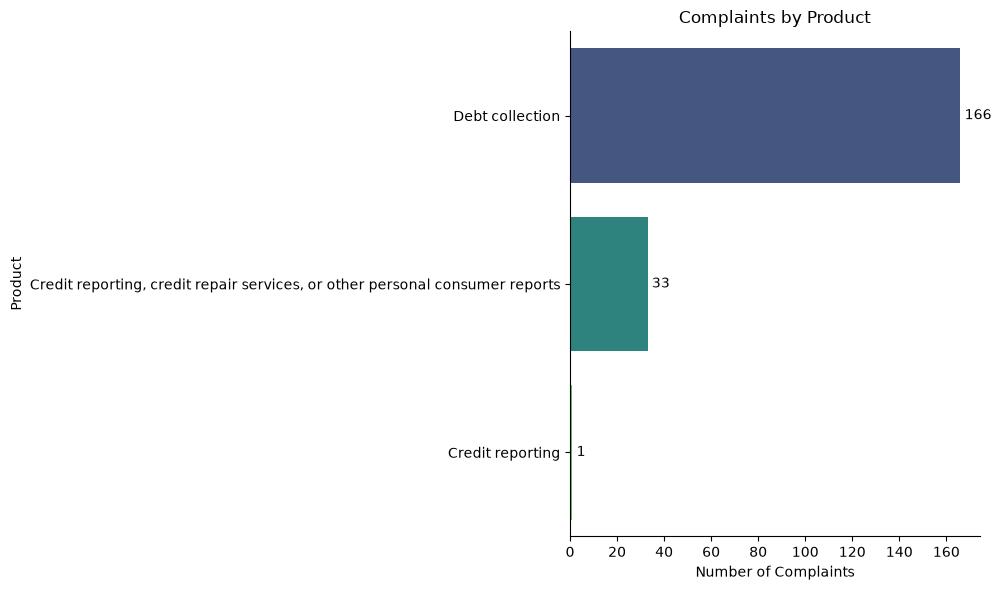

In [ ]:
# Count complaints by product
# Optional: check for missing values that countplot would silently drop
missing = df["product"].isna().sum()
if missing:
    print(f"Warning: {missing} rows with missing 'product' were excluded.")

order = df["product"].value_counts().index

plt.figure(figsize=(10, 6))
ax = sns.countplot(
    y="product",
    data=df,
    order=order,
    hue="product",
    hue_order=order,      # keeps palette aligned with bar order
    palette="viridis",
    legend=False,
)

# Add count labels at the end of each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

ax.set_title("Complaints by Product")
ax.set_xlabel("Number of Complaints")
ax.set_ylabel("Product")
sns.despine()             # remove top/right spines for a cleaner look
plt.tight_layout()
plt.show()



### Complaints by Product
## Insights: 

**Debt collection dominates.** It accounts for **166 of 200 complaints (83%)**, roughly 5x the next category.

| Product | Complaints | Share |
|---|---|---|
| Debt collection | 166 | 83.0% |
| Credit reporting, credit repair services, or other personal consumer reports | 33 | 16.5% |
| Credit reporting | 1 | 0.5% |
| **Total** | **200** | **100%** |

### Insights and Observations
- The majority of complaints are concentrated in **debt collection**, which accounts for a significantly higher number of cases compared to other products.  
- **Credit reporting and related services** appear far less frequently, but they still represent important areas of customer dissatisfaction.  
- The dominance of debt collection complaints suggests that customers are most frustrated with how debts are pursued, verified, and communicated.  
- The imbalance across products highlights that Citi Bank’s **highest risk to customer satisfaction lies in debt collection practices**.

### Recommendation
Citi Bank should:
1. **Prioritize improvements in debt collection processes** — ensure accuracy in debt verification and compliance with fair collection standards.  
2. **Enhance transparency and communication** with customers during debt recovery to reduce disputes and mistrust.  
3. **Monitor credit reporting complaints closely** to prevent escalation, even though volumes are lower.  
4. **Establish a dedicated task force** to address systemic issues in debt collection, as this is the most critical driver of dissatisfaction.

Focusing on debt collection first while maintaining vigilance in credit reporting, Citi Bank can address the largest source of complaints and strengthen overall customer trust.


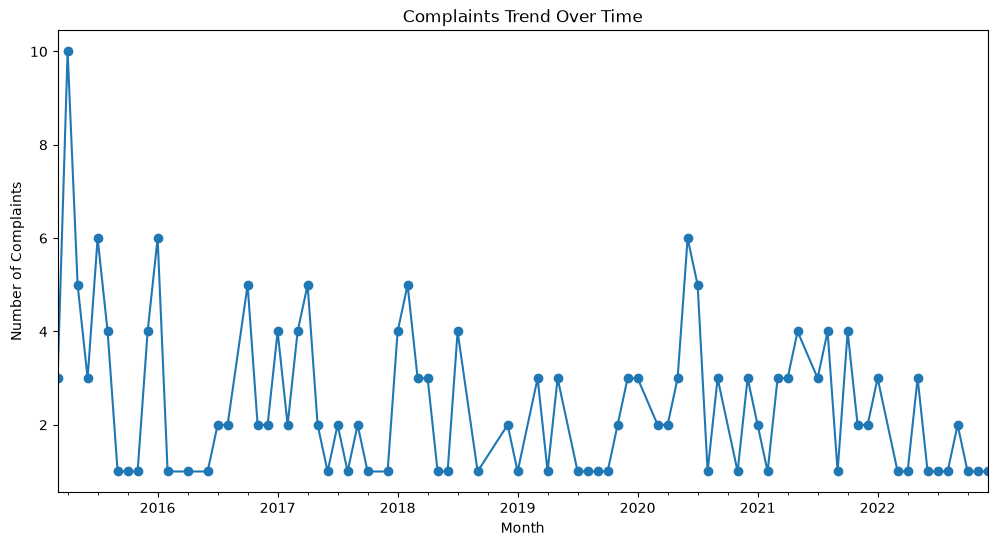

In [ ]:
# Convert date column to datetime
df['date_received'] = pd.to_datetime(df['date_received'], errors='coerce')

# Complaints per month
complaints_trend = df.groupby(df['date_received'].dt.to_period("M")).size()

plt.figure(figsize=(12,6))
complaints_trend.plot(kind='line', marker='o')
plt.title("Complaints Trend Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Complaints")
plt.show()


### Insights and Observations
- The trend shows a **general decline in the number of complaints** from 2015 through 2022, although there are **periodic spikes** in certain months.  
- The initial years (2015–2016) recorded **higher complaint volumes**, suggesting possible issues with debt collection practices or credit reporting accuracy during that period.  
- The downward trend indicates that **industry-wide improvements** may have reduced complaint frequency, but the occasional spikes highlight that **specific events or product changes** still trigger customer dissatisfaction.  
- The persistence of spikes suggests that while overall complaint management has improved, **systemic issues remain unresolved**.

### Recommendation
Citi Bank should:
1. **Investigate the causes of complaint spikes** — align them with product launches, policy changes, or external events to identify triggers.  
2. **Implement proactive monitoring** of customer feedback to detect early warning signs of dissatisfaction before they escalate.  
3. **Sustain the downward trend** by reinforcing best practices in debt collection, credit reporting accuracy, and customer communication.  
4. **Introduce continuous improvement programs** (e.g., quarterly reviews of complaint data) to ensure that recurring issues are addressed promptly.  

Focusing on both the **long-term decline** and the **short-term spikes**, Citi Bank can strengthen customer trust and maintain consistent satisfaction levels.


In [ ]:
# Top 10 issues
plt.figure(figsize=(10,6))
sns.barplot(
    x=top_issues.values,
    y=top_issues.index,
    hue=top_issues.index,   # explicitly assign hue
    palette="magma",
    legend=False            # suppress redundant legend
)
plt.title("Top 10 Complaint Issues")
plt.xlabel("Number of Complaints")
plt.ylabel("Issue")
plt.show()



NameError: name 'top_issues' is not defined

<Figure size 1000x600 with 0 Axes>

### Insights and Observations
- The most frequent complaint issue is **“Attempts to collect debt not owed”**, followed closely by **“Continued attempts to collect debt not owed.”**  
- Other recurring issues include **incorrect information on credit reports**, **false statements or representation**, and **communication tactics**.  
- These categories suggest that customers are highly sensitive to **debt collection practices** and **accuracy of credit reporting**, both of which directly affect trust in financial institutions.  
- The presence of multiple complaint types related to **debt collection and credit reporting** indicates systemic challenges in transparency, verification, and communication.

### Recommendation
Citi Bank should prioritize:
1. **Strengthening debt verification processes** to ensure customers are not wrongly pursued for debts they do not owe.  
2. **Improving accuracy in credit reporting** by collaborating closely with credit bureaus and enhancing internal data validation.  
3. **Enhancing communication protocols** to ensure customers receive clear, respectful, and compliant notifications.  

Citi Bank can reduce customer dissatisfaction, build trust, and improve overall customer satisfaction scores by addressing above issues.


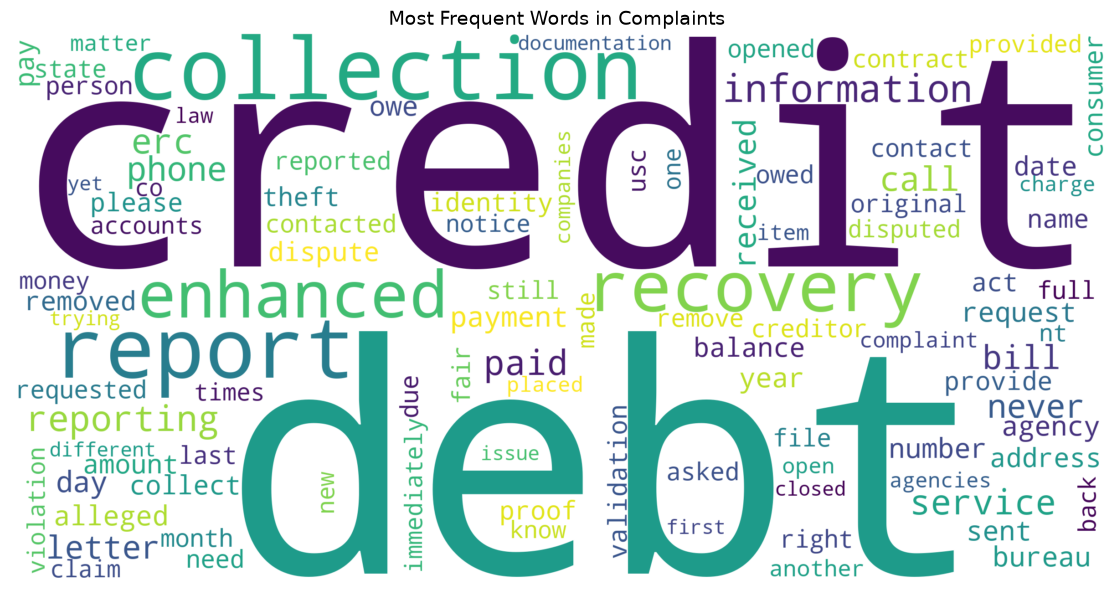

In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

# 1. Remove redaction tokens (xx, xxxx, xxxxxxxx, XX/XX/XXXX, etc.)
def remove_redactions(text):
    text = re.sub(r"\bx{2,}\b", " ", text, flags=re.IGNORECASE)  # any run of 2+ x's
    return re.sub(r"\s+", " ", text).strip()                      # tidy whitespace

all_text = " ".join(df["cleaned_text"].dropna().astype(str))
all_text = remove_redactions(all_text)

# 2. Domain stopwords
custom_stopwords = STOPWORDS.union({
    "account", "company", "told", "said", "also", "would", "called", "time"
})

# 3. Generate word cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    stopwords=custom_stopwords,
    max_words=100,
    collocations=False,      # single words only, no bigrams
    colormap="viridis",
    random_state=42,
    scale=2,
).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Complaints", fontsize=14)
plt.tight_layout()
plt.show()

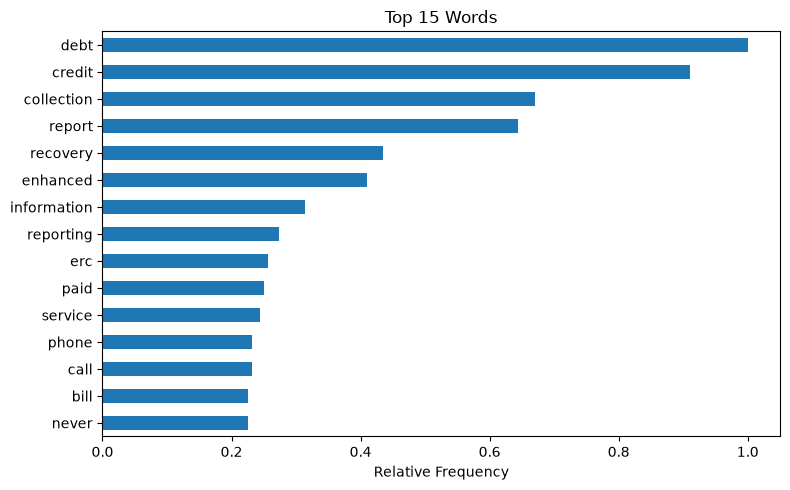

In [ ]:
# 4. Top 15 words
freq = pd.Series(wordcloud.words_).head(15)
freq.sort_values().plot(kind="barh", figsize=(8, 5), title="Top 15 Words")
plt.xlabel("Relative Frequency")
plt.tight_layout()
plt.show()

### Insights and Observations
- The most frequent words in customer complaints are **“debt,” “credit,” and “collection,”** indicating that debt collection practices and credit reporting are dominant pain points.  
- Other common terms such as **“report,” “information,” and “service”** suggest that customers are concerned about the accuracy of credit reports and the quality of communication/service they receive.  
- Words like **“phone,” “call,” and “bill”** highlight that many complaints are tied to direct interactions with debt collectors or billing processes.  
- The prominence of **“never”** may reflect customer frustration with repeated or unresolved issues, pointing to dissatisfaction with resolution processes.

### Recommendation
Citi Bank should:
1. **Audit debt collection practices** to ensure compliance and fairness, reducing instances of customers being contacted for debts they do not owe.  
2. **Enhance credit reporting accuracy** by strengthening data validation and collaborating closely with credit bureaus.  
3. **Improve customer communication channels** (phone, billing, service) to make interactions more transparent, respectful, and solution‑oriented.  

Citi Bank can reduce negative sentiment, build trust, and improve overall customer satisfaction by paying attention to above key complaints.


## Guiding Analytical Questions

To ensure our analysis is structured and aligned with Citi Bank’s customer experience goals, we define guiding questions for the next phase:

### Sentiment Analysis
1. What proportion of complaints are negative, neutral, or positive?
2. Which financial products attract the most negative sentiment?
3. How does sentiment trend over time?
4. Which issues consistently carry negative sentiment?
5. How can sentiment insights guide Citi Bank’s priorities?

### Theme Extraction
1. What recurring themes emerge from customer complaints?
2. How do themes vary by product type?
3. Which themes are most strongly associated with negative sentiment?
4. Are there emerging issues Citi Bank should address?
5. How can these themes be translated into actionable recommendations?

# Sentiment Analysis

## Purpose
We analyze the sentiment of customer complaints to measure overall satisfaction levels.  
This helps Citi Bank identify which products and issues generate the most negative sentiment, guiding improvements in customer experience.

## Approach
- Use **TextBlob** to calculate sentiment polarity scores.  
- Categorize complaints into **Positive, Neutral, Negative**.  
- Visualize sentiment distribution and compare across products and over time.


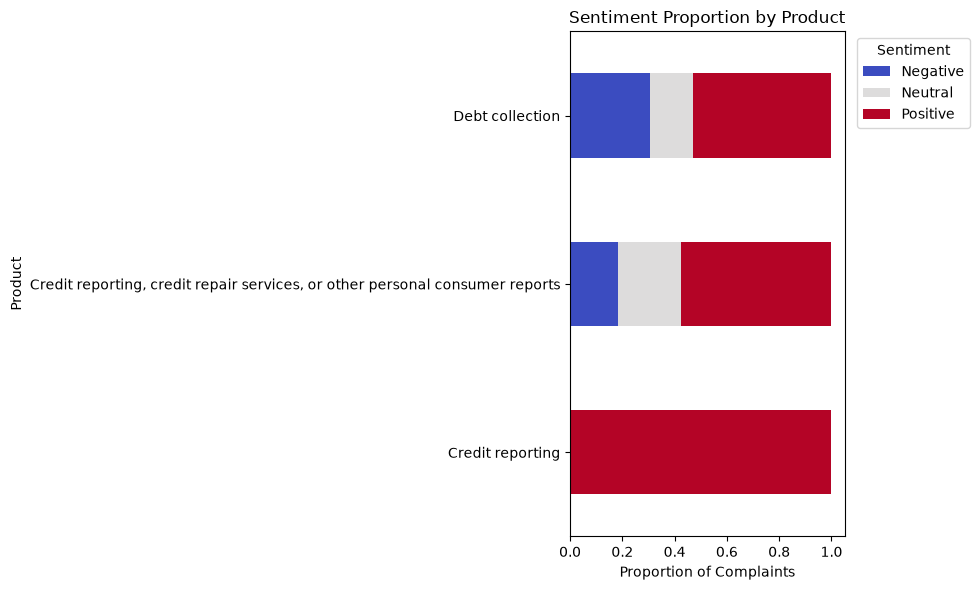

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob

# Score and categorize sentiment
df['complaint_text'] = df['complaint_text'].fillna('').astype(str)
df['polarity'] = df['complaint_text'].apply(lambda text: TextBlob(text).sentiment.polarity)
df['sentiment'] = pd.cut(
    df['polarity'],
    bins=[-float('inf'), -1e-9, 1e-9, float('inf')],
    labels=['Negative', 'Neutral', 'Positive']
)

# Proportion of each sentiment within each product
prop = pd.crosstab(df['product'], df['sentiment'], normalize='index')
prop = prop[['Negative', 'Neutral', 'Positive']]  # consistent column order

prop.plot(kind='barh', stacked=True, colormap='coolwarm', figsize=(10, 6))
plt.title('Sentiment Proportion by Product')
plt.xlabel('Proportion of Complaints')
plt.ylabel('Product')
plt.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Observations
- Positive sentiment dominates across all products. This is unusual for complaint text and may reflect TextBlob’s tendency to classify neutral‑leaning complaints as positive.  
- **Credit reporting** appears fully positive (100%), which is suspicious. This likely results from a very small sample size — check the complaint count before drawing conclusions.  
- **Debt collection** shows the highest negative share, at roughly 31%, confirming it as the most problematic product category.  
- **Credit reporting, credit repair services, or other personal consumer reports** has the largest neutral share, at about 24%, suggesting mixed experiences in this category.  

### Recommendations
- **Focus on debt collection**: With the highest negative share, this area should be prioritized for process improvements, compliance checks, and customer communication enhancements.  
- **Investigate neutral complaints**: The relatively high neutral share in credit repair services suggests ambiguity in customer experiences. A deeper qualitative review could clarify whether these are truly neutral or misclassified.  


# Theme Extraction (Topic Modeling)

## Purpose
We use Latent Dirichlet Allocation (LDA) to uncover recurring themes in customer complaints.  
This helps Citi Bank identify systemic issues such as debt collection, credit reporting, or customer service delays.

## Approach
- Convert complaint text into a document-term matrix using **CountVectorizer**.  
- Apply **LDA** to extract dominant themes.  
- Display top words per theme to interpret recurring issues.


In [ ]:
import re
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

N_TOPICS = 5
N_TOP_WORDS = 10

# Remove redaction placeholders (runs of 2+ x's as whole words, any case)
REDACTED = re.compile(r'\b[xX]{2,}\b')
texts = (df['cleaned_text'].fillna('').astype(str)
         .apply(lambda t: REDACTED.sub(' ', t)))

# Vectorize text
vectorizer = CountVectorizer(max_df=0.95, min_df=2, stop_words='english')
dtm = vectorizer.fit_transform(texts)
feature_names = vectorizer.get_feature_names_out()

# Fit LDA
lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42)
doc_topic = lda.fit_transform(dtm)

# Top words per theme, highest weight first
top_words = {
    f"Theme {i + 1}": [feature_names[j] for j in topic.argsort()[::-1][:N_TOP_WORDS]]
    for i, topic in enumerate(lda.components_)
}

for theme, words in top_words.items():
    print(f"{theme}: {', '.join(words)}")

df['dominant_theme'] = doc_topic.argmax(axis=1) + 1

Theme 1: debt, company, collection, account, credit, recovery, enhanced, called, payment, collect
Theme 2: account, debt, credit, phone, company, erc, called, collection, number, told
Theme 3: credit, account, recovery, report, debt, enhanced, collection, company, information, reporting
Theme 4: debt, credit, validation, request, collection, fair, company, act, matter, letter
Theme 5: account, credit, service, paid, told, payment, report, days, company, balance


### Theme Extraction Insights

**Theme 1: Debt Collection & Payment**
- Keywords: debt, company, collection, account, credit, recovery, payment, collect  
- Focus: Customers are frustrated with debt recovery processes and payment handling.  

**Theme 2: Communication & Contact**
- Keywords: account, debt, credit, phone, company, called, number, told  
- Focus: Complaints highlight aggressive or unclear communication tactics, especially phone calls.  

**Theme 3: Credit Reporting & Information Accuracy**
- Keywords: credit, account, recovery, report, debt, information, reporting  
- Focus: Accuracy of credit reports and information sharing is a recurring issue.  

**Theme 4: Validation & Compliance**
- Keywords: debt, credit, validation, request, collection, fair, act, letter  
- Focus: Customers demand proper validation of debts and compliance with the Fair Debt Collection Practices Act.  

**Theme 5: Account Services & Payments**
- Keywords: account, credit, service, paid, payment, report, balance  
- Focus: Issues around account servicing, billing accuracy, and payment posting are common.  

---

### Recommendations to Citi Bank
1. **Strengthen Debt Verification**  
   Ensure debts are validated before collection efforts begin. Provide customers with clear documentation to reduce disputes.  

2. **Improve Communication Practices**  
   Train agents on respectful, transparent communication. Limit repeated or aggressive phone calls and provide written notices where required.  

3. **Enhance Credit Reporting Accuracy**  
   Collaborate with credit bureaus to ensure timely updates and corrections. Implement stronger internal checks to prevent misinformation.  

4. **Ensure Regulatory Compliance**  
   Align collection practices with the Fair Debt Collection Practices Act and other consumer protection laws. Regular compliance audits should be conducted.  

5. **Optimize Account Services**  
   Improve billing accuracy, payment posting, and account balance transparency. Offer digital tools for customers to track payments and resolve issues quickly.  


# Project Summary and Recommendations

## Key Findings
- **Debt collection** dominates complaints and carries the highest negative sentiment.  
- **Credit reporting** shows suspiciously positive sentiment, likely due to small sample size or TextBlob bias.  
- **Recurring themes** include debt verification, communication practices, credit reporting accuracy, regulatory compliance, and account servicing.  
- Complaint trends show a long‑term decline but periodic spikes, suggesting unresolved systemic issues.

## Recommendations to Citi Bank
1. **Strengthen debt verification and compliance** to reduce wrongful collection attempts.  
2. **Improve communication practices** by ensuring respectful, transparent, and compliant customer interactions.  
3. **Enhance credit reporting accuracy** through stronger data validation and collaboration with bureaus.  
4. **Optimize account services** — billing accuracy, payment posting, and balance transparency.  
5. **Validate sentiment analysis tools** (e.g., VADER) to ensure accurate measurement of customer sentiment.  
6. **Continuous monitoring** — quarterly reviews of complaint data to detect emerging issues and measure improvements.

## Conclusion
Together, **EDA, sentiment analysis, and theme extraction** give Citi Bank a clear picture of where customers are struggling. Improving debt collection practices, communication, and credit reporting accuracy is likely to build greater customer trust and satisfaction.
